# Experiment 4 — GP-Based Equivalent of Bays (2014) Figure 4

> **Standalone note.** This notebook is **Experiment 4 only** (Bays Fig 4 robustness). Experiment 5 (baseline identifiability, which *fits* the GP model to the Bays cache) now lives in its own notebook. As the control cell below states, `DISTRIBUTION`/`MODEL` here only tag the output directory — the robustness panels are built from the shared periodic kernel, not the heterogeneous sampler.


## Robustness of error distributions under tuning and noise variations

This notebook reproduces the qualitative structure of Bays (2014) Figure 4 using the
GP population-coding framework. Each column tests robustness against one variation
of the homogeneous, uncorrelated, zero-baseline base model.

### Kernel / ω convention (unchanged from previous version)

This notebook uses the periodic kernel `exp(−2 sin²(d/2) / λ²)`, which maps exactly
onto Bays's von Mises tuning: `κ = 1/λ²`, hence `ω = κ⁻¹ = λ²` and `λ = √ω`.
This is intentionally **different** from `core/encoder/gaussian_process.py`, which uses
`exp(−d²_circ / (2λ²))` with `ω = 1/λ²`. The two parameterise tuning width oppositely
in `λ`. The notebook is self-contained and does not import from `core`, so there is no
cross-talk; the `λ` constants below are correct *for this kernel*.

### Panels

| Panel | Manipulation | Implementation |
|-------|-------------|---------------|
| **a** | Broad GP tuning (ω = 0.5)  | λ = √0.5 ≈ 0.707, shared-kernel GP |
| **b** | Narrow GP tuning (ω = 0.2) | λ = √0.2 ≈ 0.447, shared-kernel GP |
| **c** | Baseline activity (f₀ = 0.25 of peak) | narrow GP + constant floor |
| **d** | von Mises tuning (ω = 0.5) | parametric Bays baseline, evenly spaced φᵢ |
| **e** | Cosine tuning | half-wave-rectified cos, random preferred orientations |
| **f** | Correlated activity (c₀ = 0.25) | narrow GP + latent-Gaussian correlated Poisson; M ∈ {100, 1000} |


## What changed in this version (thesis corrections)

The robustness experiment itself is unchanged: the six populations (broad, narrow,
baseline, von Mises, cosine, correlated), their constructions and parameters, the
gain sweep (1-128 Hz total), the trial engine, the decoder, the KDE and the
matched-variance von Mises deviation are all exactly as before.

What changed:

1. **Population seeds (Correction 3).** The whole experiment is repeated at
   `N_SEEDS` independent population draws (new tuning curves and new trials).
   Seed 0 uses the original seeds, so it reproduces the single-seed run exactly.
   The von Mises population (panel d) is deterministic, so only its trials vary.
2. **Seed-averaged summaries.** For every panel, gain and population size: circular
   variance, circular kurtosis and the size of the deviation from the matched von
   Mises, each as a mean with a 95% confidence interval across seeds.
3. **Figure (Correction 7).** Curves are means over seeds, with 95% bands on the
   deviation row; every axis has labelled ticks; the cell prints the axis and
   colour scales for the caption.
4. **Housekeeping.** Results are saved under `simulated_experiments/bays_2014/
   result_data` (the old path pointed at a folder that no longer exists), and the
   panel-f loop no longer overwrites the global `M`. Each (panel, seed) result is
   cached to disk, so an interrupted run resumes where it stopped.

In [2]:
import os
os.makedirs('result_data', exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from scipy.stats import vonmises, norm, poisson
from scipy.special import i0
import time
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 150


### Core Methods

In [3]:
def periodic_kernel(thetas, lengthscale):
    """
    Periodic kernel that maps onto Bays's von Mises tuning exactly:

        K(θ, θ') = exp(−2 sin²(|θ−θ'|/2) / λ²)

    From the identity exp(κ(cos d − 1)) = exp(−2κ sin²(d/2)),
    setting κ = 1/λ² gives ω = κ⁻¹ = λ². So λ = √ω.

    Note: this differs from `core/encoder/gaussian_process.py`, which uses
    exp(−d²_circ / (2λ²)) where ω = 1/λ². The two parameterise width oppositely.
    """
    diff = thetas[:, None] - thetas[None, :]
    return np.exp(-2.0 * np.sin(diff / 2.0)**2 / lengthscale**2)


def make_gp_population_shared_kernel(M, n_theta, lengthscale, seed):
    """
    Sample M GP tuning curves that share a single kernel (panels a, b, c, e).

    Cholesky is computed once and reused — much faster than the per-neuron
    Cholesky used by the heterogeneous generator.
    """
    rng = np.random.RandomState(seed)
    thetas = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
    K = periodic_kernel(thetas, lengthscale)
    L_chol = np.linalg.cholesky(K + 1e-8 * np.eye(n_theta))
    Z = rng.randn(M, n_theta)              # i.i.d. latent normals
    F = Z @ L_chol.T                       # GP samples in log-space, shape (M, n_theta)
    g = np.exp(F)                          # positive tuning, shape (M, n_theta)
    return thetas, g


def dn_pointwise(g_col, gamma, sigma_sq, mean_g):
    """Divisive normalisation: r_i = γ · g_i / (σ² + ḡ).

    Equivalent to core/encoder/divisive_normalization.dn_pointwise; ḡ is computed
    once outside (one value per orientation) so this is just the per-θ slice.
    """
    return gamma * g_col / (sigma_sq + mean_g)


def generate_spikes(rates, T_d, rng):
    """Independent Poisson spikes (matches core/encoder/poisson_spike.generate_spikes)."""
    return rng.poisson(np.maximum(rates * T_d, 0.0))


def circular_error(theta_true, theta_hat):
    """Signed circular distance in [−π, π)."""
    return np.angle(np.exp(1j * (theta_hat - theta_true)))

### Trigonometric interpolation: storage grid → decoder grid

The tuning curves are stored on `N_THETA` orientation bins. The ML decoder
needs a finer grid — Bays uses 1000 points — so that at high gain the argmax
isn't quantised. We upsample using FFT-based trigonometric interpolation,
which is exact for periodic functions sampled on `N_THETA` evenly spaced points.

For each neuron, we compute `log g` on `N_DECODE` points and use that as the
decoder's tuning. The DN denominator and the spike-generation step still
operate on the storage grid (so the ground-truth orientation is one of
`N_THETA` discrete values), but the decoder evaluates the log-likelihood on
`N_DECODE` points, finding a much sharper maximum.


In [4]:
def trig_interp_periodic(y_coarse, n_fine):
    """
    Trigonometric (FFT-based) interpolation of a periodic signal.

    Takes y sampled on n evenly-spaced points in [−π, π) and returns y on
    n_fine evenly-spaced points in the same interval. Exact for band-limited
    functions with bandwidth ≤ n/2.

    Implementation: take FFT, zero-pad in frequency, inverse FFT, scale.
    """
    n = y_coarse.shape[-1]
    if n_fine == n:
        return y_coarse.copy()
    Y = np.fft.fft(y_coarse, axis=-1)
    pad_shape = list(y_coarse.shape)
    pad_shape[-1] = n_fine - n
    # Even n: split the Nyquist component when zero-padding
    half = n // 2
    Y_pad = np.concatenate([
        Y[..., :half],
        np.zeros(pad_shape, dtype=Y.dtype),
        Y[..., half:],
    ], axis=-1)
    return np.real(np.fft.ifft(Y_pad, axis=-1)) * (n_fine / n)


def upsample_log_tuning(g, n_decode):
    """
    Upsample log(g) to a fine grid for decoding.

    We interpolate log(g) rather than g because the decoder uses log-rates,
    and log-tuning is smoother (typical GP draws have positive tuning that
    spans 1–2 orders of magnitude — log-space interpolation is much more
    faithful than linear-space interpolation followed by log).
    """
    log_g = np.log(np.maximum(g, 1e-30))
    return trig_interp_periodic(log_g, n_decode)

In [5]:
def estimate_kappa_ml(errors):
    """ML estimate of von Mises κ via Mardia–Jupp piecewise approximation."""
    R_bar = np.abs(np.mean(np.exp(1j * errors)))
    R_bar = np.clip(R_bar, 1e-10, 1.0 - 1e-10)
    if R_bar < 0.53:
        kappa = 2 * R_bar + R_bar**3 + 5 * R_bar**5 / 6
    elif R_bar < 0.85:
        kappa = -0.4 + 1.39 * R_bar + 0.43 / (1 - R_bar)
    else:
        kappa = 1.0 / (2*(1 - R_bar) - (1 - R_bar)**2 - (1 - R_bar)**3)
    return max(kappa, 0.01)


def vm_kde(errors, eval_pts, kappa_kde):
    """
    Von Mises kernel density estimate on the circle.

        p̂(θ) = (1/n) Σⱼ vM(θ; μ = errors[j], κ = κ_kde)
              = (1/n) (1/(2π I₀(κ_kde))) Σⱼ exp(κ_kde · cos(θ − errors[j]))

    Bandwidth is controlled by κ_kde (larger = tighter kernel). κ_kde ≈ 1/bw²
    for a Gaussian KDE with bandwidth bw, so bw = 0.2 → κ_kde ≈ 25.
    """
    d = eval_pts[:, None] - errors[None, :]   # (n_eval, n_samples)
    log_w = kappa_kde * np.cos(d)
    # Stable mean of exp(log_w) along sample axis
    m = log_w.max(axis=1, keepdims=True)
    weights = np.exp(log_w - m)
    p = (weights.mean(axis=1) * np.exp(m.squeeze())) / (2.0 * np.pi * i0(kappa_kde))
    return p


def compute_deviation(errors, n_eval=400, kappa_kde_min=25.0,
                      adaptive_kde=True):
    """
    KDE-smoothed empirical density and its deviation from a best-fit von Mises.

    With `adaptive_kde=True` (the default), the KDE concentration scales as
    κ_kde = max(κ_kde_min, 10 · κ_fit). The 10× multiplier (rather than 0.5×
    as in the original code, or 1× as a naive fix) reflects what bandwidth
    diagnostics actually require:

      • The deviation Δ = empirical − vM is computed by KDE-smoothing the
        sampled errors and subtracting a vM with the same circular variance.
      • If κ_kde is *smaller* than κ_fit (wider kernel than the reference
        distribution), the KDE spreads the peak laterally, depressing the
        density estimate at zero. Subtracting a vM with the correct κ_fit
        then yields a spurious negative trough at zero — the deviation
        gets the wrong sign.
      • If κ_kde is *larger* than κ_fit (narrower kernel than the reference
        distribution), the KDE follows the empirical density faithfully
        without lateral smoothing bias, and the sign of Δ(0) matches the
        raw histogram.

    Diagnostic sweep at γ_total = 128 on the homogeneous vM population
    (κ_fit ≈ 16) confirmed this: κ_kde = 25 gave Δ(0) ≈ −0.33 (wrong sign);
    κ_kde = 200 gave Δ(0) ≈ +0.01 (correct sign, matches raw histogram).
    The 10× rule gives κ_kde ≈ 160 here, safely in the correct-sign regime.

    Returns the signed difference (empirical − vM) so that the bottom row of
    the figure visualises where the empirical distribution exceeds (positive
    bumps) or falls short of (negative dips) the matched-variance von Mises.
    """
    eval_pts = np.linspace(-np.pi, np.pi, n_eval, endpoint=False)
    kappa_fit = estimate_kappa_ml(errors)
    vm_pdf = vonmises.pdf(eval_pts, kappa_fit)
    if adaptive_kde:
        kappa_kde = max(kappa_kde_min, 10.0 * kappa_fit)
    else:
        kappa_kde = kappa_kde_min
    emp = vm_kde(errors, eval_pts, kappa_kde)
    return {
        'centers': eval_pts,
        'empirical': emp,
        'von_mises': vm_pdf,
        'deviation': emp - vm_pdf,
        'kappa_fit': kappa_fit,
        'kappa_kde': kappa_kde,
    }

### Population generators

In [6]:
def make_gp_with_baseline(M, n_theta, lengthscale, baseline_frac, seed):
    """
    Homogeneous GP + constant baseline floor (panel c).

    The baseline f₀ is set so that f₀ / (f₀ + peak) = baseline_frac, matching
    Bays's "fraction of peak activation" convention (his Methods, Fig 4c).
    """
    thetas, g = make_gp_population_shared_kernel(M, n_theta, lengthscale, seed)
    if baseline_frac > 1e-10:
        mean_peak = np.mean(np.max(g, axis=1))
        f0 = baseline_frac * mean_peak / (1.0 - baseline_frac)
        g = g + f0
    return thetas, g


def make_cosine_population(M, n_theta, seed,
                           amp_mean=1.0, amp_std=0.5,
                           bl_mean=0.25, bl_std=0.125):
    """
    Half-wave-rectified cosine tuning with random preferred orientations
    (panel d, matching Bays Eq. 18).

        f_i(θ) = aᵢ · max(0, cos(θ − φᵢ)) + bᵢ

    where φᵢ ~ U(−π, π), aᵢ ~ |N(1, 0.5)|, bᵢ ~ |N(0.25, 0.125)|.
    """
    rng = np.random.RandomState(seed)
    thetas = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
    prefs = rng.uniform(-np.pi, np.pi, M)
    amps = np.abs(rng.normal(amp_mean, amp_std, M))
    bls = np.abs(rng.normal(bl_mean,  bl_std,  M))
    diff = thetas[None, :] - prefs[:, None]
    g = amps[:, None] * np.maximum(0.0, np.cos(diff)) + bls[:, None]
    return thetas, g

def make_vm_population(M, n_theta, omega, seed):
    """
    Homogeneous von Mises tuning (Bays Eq. 1) — the parametric baseline.

        f_i(θ) = exp(κ(cos(θ − φ_i) − 1))

    where κ = 1/ω and preferred orientations φᵢ are evenly spaced on [−π, π).
    This is what Bays uses in his basic model. Including it here lets us read
    off how much of the GP-column behaviour is inherited from Bays vs. created
    by GP heterogeneity.

    The `seed` argument is accepted for signature compatibility with the other
    generators; the von Mises population is deterministic given (M, n_theta, ω).
    """
    thetas = np.linspace(-np.pi, np.pi, n_theta, endpoint=False)
    prefs = np.linspace(-np.pi, np.pi, M, endpoint=False)
    kappa = 1.0 / omega
    diff = thetas[None, :] - prefs[:, None]          # (M, n_theta)
    g = np.exp(kappa * (np.cos(diff) - 1.0))
    return thetas, g



### Correlated spike generation (panel e)

Short-range correlations: `c_ij = c₀ exp(−|φ_i − φ_j|)` (Bays Eq. 19), generated via
the latent-Gaussian copula method of Macke et al. (2008).

For a homogeneous Bays population, `φ_i` is the preferred orientation. Our GP neurons
don't have a single preferred orientation (each is a random function), so we assign
`φ_i = i · 2π/M` as an arbitrary index-based label — neurons that are neighbours by
index are correlated. This is a structurally valid correlation matrix; it just no
longer means *"neurons with similar tuning are correlated"* in the Bays sense. The
qualitative point of the panel — short-range correlations interact with population
size in a way that the other manipulations don't — survives this re-interpretation.


In [7]:
def build_correlation_matrix(M, c0):
    """Short-range pairwise correlations on M neurons indexed by [−π, π).

    Index-based (legacy / Bays-faithful) construction:

        c_ij = c0 · exp(−|φ_i − φ_j|),   φ_i = i · 2π/M

    In Bays's homogeneous von Mises model, neuron i has preferred orientation
    φ_i = i · 2π/M, so "neurons with similar index" and "neurons with similar
    preferred orientation" are the same set. The exponential decay then maps
    onto the biological intuition that similarly-tuned cells share noise.

    In the GP framework, neurons don't have a single preferred orientation
    (each is a random function), so the φ_i used here is a *fictitious*
    index-based label — neighbours by index are correlated regardless of
    whether their tuning curves resemble each other. The matrix is
    structurally a valid Bays correlation matrix; the semantic claim
    ("similar-tuning cells share noise") just doesn't survive the substrate
    change. The qualitative point of the panel — that short-range
    correlations interact with population size in a way the other panel
    manipulations don't — is preserved either way.
    """
    prefs = np.linspace(-np.pi, np.pi, M, endpoint=False)
    diff = np.abs(prefs[:, None] - prefs[None, :])
    diff = np.minimum(diff, 2 * np.pi - diff)
    C = c0 * np.exp(-diff)
    np.fill_diagonal(C, 1.0)
    return C, prefs


def precompute_cholesky(corr_matrix):
    """Cholesky with eigenvalue-clamp + ridge fallback.

    The original clamp at 1e-6 was tight enough for the smooth index-based
    correlation matrix at M = 100, but borderline at M = 1000 and brittle
    if the construction is ever changed. The fallback path now re-
    symmetrises, clamps eigenvalues to 1e-4, and adds a small diagonal
    ridge before retrying — none of which perturbs the matrix structure
    meaningfully but all of which guarantee a numerically clean Cholesky.
    """
    try:
        return np.linalg.cholesky(corr_matrix)
    except np.linalg.LinAlgError:
        C_sym = 0.5 * (corr_matrix + corr_matrix.T)
        eigvals, eigvecs = np.linalg.eigh(C_sym)
        eigvals = np.maximum(eigvals, 1e-4)
        C_fixed = eigvecs @ np.diag(eigvals) @ eigvecs.T
        C_fixed = 0.5 * (C_fixed + C_fixed.T)
        np.fill_diagonal(C_fixed, 1.0)
        C_fixed = C_fixed + 1e-6 * np.eye(C_fixed.shape[0])
        return np.linalg.cholesky(C_fixed)


def generate_correlated_spikes(rates, T_d, chol_L, rng):
    """Correlated Poisson via latent Gaussian copula (Macke et al. 2008)."""
    M = len(rates)
    lambdas = np.maximum(rates * T_d, 1e-10)
    z = chol_L @ rng.randn(M)
    u = np.clip(norm.cdf(z), 1e-10, 1.0 - 1e-10)
    counts = poisson.ppf(u, mu=lambdas).astype(int)
    return np.maximum(counts, 0)

### Trial engine (vectorised over trials)

In [8]:
def run_trials(g, thetas, gamma, T_d, sigma_sq, n_trials, rng,
               n_decode=1000, chol_L=None):
    """
    Encode → DN → spike → decode → error, vectorised over trials.

    Pipeline (matches the equations in Bays §Materials & Methods, Eqs. 1–8):
      1. Pick a true orientation index uniformly from the n_theta storage grid.
      2. Compute pre-DN driving inputs g_i(θ_true) for all neurons.
      3. Apply DN: r_i = γ · g_i / (σ² + ḡ).  ḡ is precomputed per storage-θ.
      4. Generate Poisson spikes (independent or correlated via chol_L).
      5. Decode on the *fine* grid: argmax_θ counts · log_g_fine(θ).
      6. Return signed circular error θ̂ − θ_true.

    Decoder fix: no rate-sum penalty — under DN with σ² → 0, Σᵢ rᵢ(θ) is θ-
    independent (Activity Cap), so the second term in Bays Eq. 6 drops from
    argmax. This is exact under our σ² = 1e-6.

    Parameters
    ----------
    g : (M, n_theta) — pre-DN driving inputs on storage grid.
    thetas : (n_theta,) — storage-grid orientations.
    gamma, T_d, sigma_sq : floats.
    n_trials : int.
    n_decode : int — fine decoder grid size (≥ n_theta).
    chol_L : optional (M, M) — Cholesky of latent-Gaussian correlation matrix.

    Returns
    -------
    errors : (n_trials,) — signed circular errors in [−π, π).
    """
    M, n_theta = g.shape

    # Decoder grid: log-tuning upsampled to n_decode points
    log_g_fine = upsample_log_tuning(g, n_decode)            # (M, n_decode)
    thetas_fine = np.linspace(-np.pi, np.pi, n_decode, endpoint=False)

    # DN denominator (per storage-θ): ḡ(θ) = mean over neurons of g(θ)
    mean_g = np.mean(g, axis=0)                              # (n_theta,)

    # Sample true orientation indices for all trials at once
    idx_true = rng.randint(0, n_theta, size=n_trials)        # (n_trials,)

    # Pre-DN rates per trial: g[:, idx_true].T has shape (n_trials, M)
    rates_pre = g[:, idx_true].T                             # (n_trials, M)
    rates = gamma * rates_pre / (sigma_sq + mean_g[idx_true])[:, None]  # (n_trials, M)

    # Spike generation
    if chol_L is None:
        # Independent Poisson — fully vectorised
        counts = generate_spikes(rates, T_d, rng)            # (n_trials, M)
    else:
        # Correlated: must loop over trials (latent Gaussian draws are per-trial)
        counts = np.empty_like(rates, dtype=np.int64)
        for t in range(n_trials):
            counts[t] = generate_correlated_spikes(rates[t], T_d, chol_L, rng)

    # Decode: ll[t, j] = Σ_i counts[t, i] · log_g_fine[i, j]
    # Single matmul over all trials.
    ll = counts @ log_g_fine                                  # (n_trials, n_decode)
    idx_hat = np.argmax(ll, axis=1)                          # (n_trials,)

    errors = circular_error(thetas[idx_true], thetas_fine[idx_hat])
    return errors

### Configuration

### GP experiment control

This notebook's GP populations are **homogeneous and self-contained**: they are built directly from a shared periodic kernel rather than from the heterogeneous-lengthscale sampler used in Figures 2/3/5. There is therefore no *functional* `DISTRIBUTION` choice here — every panel uses the same shared-kernel GP, with the panel-specific variations (baseline activity, cosine tuning, correlations, von Mises) introduced on top. For consistency with experiment 2, the control cell below still exposes **`M`**, **`DISTRIBUTION`**, and **`MODEL`**, and writes outputs into the same `result_data/<tag>/<date>/<distribution>_<M>_<model>/<time>` layout — but here `DISTRIBUTION` / `MODEL` only *tag the output directory*; they do not change the populations.

The one knob worth pulling out as an experiment control is **`M`** (population size), which:

- Drives the homogeneous panels (a, b, c, d, the von Mises column) when set to `M_DEFAULT`.
- Drives the `M=100` curves in the correlated-activity panel f (panel f also runs at `M=1000` as a within-panel comparison, hard-coded).
- Becomes `M_F5` for the Figure 5 baseline-activity diagnostic further down.

Suggested values: `100` (primary reference, fast), `1000` (large-population diagnostic, slower).


In [9]:
# === EXPERIMENT CONTROL (M / DISTRIBUTION / MODEL / seeds) — mirrors experiment_2 ===
# NOTE: unlike Figures 2/3/5, this notebook builds its GP populations from a
# shared periodic kernel, so the populations are homogeneous by construction
# and do NOT flow from a DISTRIBUTION sampler or a MODEL dispatcher. The
# DISTRIBUTION and MODEL knobs below are defined only so this notebook writes
# its outputs into the SAME
#   result_data/<tag>/<date>/<distribution>_<M>_<model>/<time>
# directory layout as experiment_2. The heterogeneity that matters here lives
# in the per-panel variations (baseline activity, cosine tuning, correlations,
# von Mises), not in these knobs.

import sys
import datetime
from pathlib import Path

M            = 1000              # 100 / 1000
DISTRIBUTION = 'shared_kernel'   # output-path tag only (homogeneous shared-kernel GP)
MODEL        = 'gp'              # output-path tag only ('gp' is the only model here)

# --- Population seeds (Correction 3) ------------------------------------------
# Replicate s shifts every original seed by s * SEED_STRIDE: new tuning curves and
# new trials. Replicate 0 reproduces the original single-seed run exactly.
N_SEEDS     = 10
SEED_STRIDE = 1_000_000

# Kept permissive: 'shared_kernel' is the honest default for this notebook,
# but the experiment_2 sampler names are allowed too so a run can be tagged
# to sit alongside an experiment_2 run if desired.
assert DISTRIBUTION in ('shared_kernel', 'folded_normal', 'gamma', 'sparse_sharp'), DISTRIBUTION
assert MODEL in ('gp', 'vm', 'bays'), MODEL
assert N_SEEDS >= 2, 'confidence intervals need at least two seeds'

# --- ONE shared output directory for this run (experiment_2-style layout) ---
#   result_data / experiment_4 / <date> / <distribution>_<M>_<model>_<n>seeds / <time>
PROJECT_ROOT   = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:          # for core.metrics (summary statistics)
    sys.path.insert(0, str(PROJECT_ROOT))
EXPERIMENTS_DIR = PROJECT_ROOT / 'simulated_experiments' / 'bays_2014'
assert EXPERIMENTS_DIR.is_dir(), f'Expected the bays_2014 folder at {EXPERIMENTS_DIR}'
EXPERIMENT_TAG = 'experiment_4'
_date = datetime.datetime.now().strftime('%Y%m%d')
_time = datetime.datetime.now().strftime('%H%M%S')
RESULT_BASE = EXPERIMENTS_DIR / 'result_data'
OUTPUT_DIR  = (RESULT_BASE / EXPERIMENT_TAG / _date /
               f'{DISTRIBUTION}_{M}_{MODEL}_{N_SEEDS}seeds' / _time)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('=== GP experiment control (global) ===')
print(f'  M            = {M}')
print(f'  DISTRIBUTION = {DISTRIBUTION!r}  (output-path tag only)')
print(f'  MODEL        = {MODEL!r}  (output-path tag only)')
print(f'  (DISTRIBUTION/MODEL do not change the populations here — see the markdown above.)')
print(f'  N_SEEDS      = {N_SEEDS}')
print(f'  OUTPUT_DIR   = {OUTPUT_DIR}')

=== GP experiment control (global) ===
  M            = 1000
  DISTRIBUTION = 'shared_kernel'  (output-path tag only)
  MODEL        = 'gp'  (output-path tag only)
  (DISTRIBUTION/MODEL do not change the populations here — see the markdown above.)
  N_SEEDS      = 10
  OUTPUT_DIR   = /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_4/20261020/shared_kernel_1000_gp_10seeds/150741


In [10]:
N_THETA   = 128            # storage grid size
N_DECODE  = 1000           # decoder evaluation grid (matches Bays's Methods)
N_TRIALS  = 5000           # per (panel, gain) — was 3000
N_TRIALS_LARGE = 2500      # for M=1000 panel — was 1500
T_D       = 0.1
SIGMA_SQ  = 1e-6

# Tuning widths (kernel: exp(−2 sin²(d/2)/λ²), so ω = λ²)
LAMBDA_BROAD  = np.sqrt(0.5)    # ω = 0.5
LAMBDA_NARROW = np.sqrt(0.2)    # ω = 0.2
BASELINE_FRAC = 0.25            # fraction of peak (Bays Fig 4c)
C0            = 0.25            # short-range correlation amplitude (Bays Fig 4f)

# γ values match Bays Fig 4: γ_total from 1 to 128 Hz.
# Per-neuron γ inside dn_pointwise = γ_total / M (so total post-DN ≈ γ_total).
GAMMAS_TOTAL = [1, 2, 4, 8, 16, 32, 64, 128]
M_DEFAULT    = M   # picked up from the experiment-control cell above

# KDE bandwidth: minimum κ_kde ≈ 25 ↔ Gaussian bandwidth ≈ 0.2 rad. The
# adaptive rule in compute_deviation tightens this when the data themselves
# are tightly concentrated, to keep the deviation comparison well-posed.
KAPPA_KDE = 25.0
N_EVAL    = 400
SEED      = 42

print(f"Storage grid:  {N_THETA} points")
print(f"Decoder grid:  {N_DECODE} points  (resolution {2*np.pi/N_DECODE:.4f} rad)")
print(f"Total γ range: {GAMMAS_TOTAL[0]}–{GAMMAS_TOTAL[-1]} Hz")
print(f"Expected total spikes/trial range: "
      f"{GAMMAS_TOTAL[0]*T_D:.2f} → {GAMMAS_TOTAL[-1]*T_D:.2f}")
print(f"Kernel: exp(−2 sin²(d/2)/λ²); ω = λ²")
print(f"  broad:  λ = {LAMBDA_BROAD:.3f}  →  ω = {LAMBDA_BROAD**2:.2f}")
print(f"  narrow: λ = {LAMBDA_NARROW:.3f}  →  ω = {LAMBDA_NARROW**2:.2f}")


Storage grid:  128 points
Decoder grid:  1000 points  (resolution 0.0063 rad)
Total γ range: 1–128 Hz
Expected total spikes/trial range: 0.10 → 12.80
Kernel: exp(−2 sin²(d/2)/λ²); ω = λ²
  broad:  λ = 0.707  →  ω = 0.50
  narrow: λ = 0.447  →  ω = 0.20


### Run all six panels at every population seed

Panels a-e use `M_DEFAULT`; panel f (correlated activity) uses both M = 100 and
M = 1000 to expose the population-size dependence of short-range correlations
(Bays Fig 4f). Every (panel, seed) result is cached to disk as it finishes.

In [11]:
# === Run all six panels at every population seed ===
import hashlib, json as _json, pickle
from core.metrics import circular_variance_fisher, circular_kurtosis_fisher

CACHE_DIR = RESULT_BASE / 'sim_cache' / EXPERIMENT_TAG
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RERUN = False            # True ignores cached (panel, seed) results

panel_generators = {
    'a': ('Broad GP\ntuning',
          lambda M, s: make_gp_population_shared_kernel(M, N_THETA, LAMBDA_BROAD, s)),
    'b': ('Narrow GP\ntuning',
          lambda M, s: make_gp_population_shared_kernel(M, N_THETA, LAMBDA_NARROW, s)),
    'c': ('Baseline\nactivity',
          lambda M, s: make_gp_with_baseline(M, N_THETA, LAMBDA_NARROW, BASELINE_FRAC, s)),
    'd': ('von Mises\ntuning',
          lambda M, s: make_vm_population(M, N_THETA, LAMBDA_BROAD**2, s)),
    'e': ('Cosine\ntuning',
          lambda M, s: make_cosine_population(M, N_THETA, s)),
}
PANEL_IDS = ['a', 'b', 'c', 'd', 'e', 'f']
PANEL_TITLES = {pid: title for pid, (title, _) in panel_generators.items()}
PANEL_TITLES['f'] = 'Correlated\nactivity'
M_F_SIZES = [100, 1000]                       # panel f population sizes (as before)

_run_config = {
    'N_THETA': N_THETA, 'N_DECODE': N_DECODE, 'N_TRIALS': N_TRIALS,
    'N_TRIALS_LARGE': N_TRIALS_LARGE, 'T_D': T_D, 'SIGMA_SQ': SIGMA_SQ,
    'LAMBDA_BROAD': LAMBDA_BROAD, 'LAMBDA_NARROW': LAMBDA_NARROW,
    'BASELINE_FRAC': BASELINE_FRAC, 'C0': C0, 'GAMMAS_TOTAL': GAMMAS_TOTAL,
    'M_DEFAULT': M_DEFAULT, 'M_F_SIZES': M_F_SIZES, 'KAPPA_KDE': KAPPA_KDE,
    'N_EVAL': N_EVAL, 'SEED': SEED, 'SEED_STRIDE': SEED_STRIDE,
    'stage': 'fig4_multiseed_v1',
}


def _cache_file(pid, s):
    key = hashlib.md5(_json.dumps({**_run_config, 'panel': pid, 'seed_index': s},
                                  sort_keys=True, default=str).encode()).hexdigest()[:12]
    return CACHE_DIR / f'fig4_panel{pid}_seed{s}_{key}.pkl'


def _moments(errs):
    return {'variance': circular_variance_fisher(errs),
            'kurtosis': circular_kurtosis_fisher(errs)}


def run_panel_seed(pid, s):
    """One panel at one population seed. With s = 0 the seeds, populations and
    trials are exactly those of the original single-seed run."""
    shift = s * SEED_STRIDE
    out = {'results': {}, 'moments': {}}
    if pid != 'f':
        _, gen_fn = panel_generators[pid]
        thetas, g = gen_fn(M_DEFAULT, SEED + ord(pid) + shift)
        out['thetas'], out['pop_sizes'] = thetas, [M_DEFAULT]
        if s == 0:
            out['g'] = g                                   # example population for row 1
        for gt in GAMMAS_TOTAL:
            rng = np.random.RandomState(SEED + 100 + gt + shift)
            errs = run_trials(g, thetas, gt / M_DEFAULT, T_D, SIGMA_SQ,
                              N_TRIALS, rng, n_decode=N_DECODE)
            out['results'][(gt, M_DEFAULT)] = compute_deviation(
                errs, n_eval=N_EVAL, kappa_kde_min=KAPPA_KDE)
            out['moments'][(gt, M_DEFAULT)] = _moments(errs)
    else:
        out['pop_sizes'] = list(M_F_SIZES)
        for M_f in M_F_SIZES:                              # (no longer overwrites M)
            thetas, g = make_gp_population_shared_kernel(
                M_f, N_THETA, LAMBDA_NARROW, SEED + M_f + 500 + shift)
            corr_mat, neuron_prefs = build_correlation_matrix(M_f, C0)
            chol_L = precompute_cholesky(corr_mat)
            out['thetas'] = thetas
            if s == 0 and M_f == M_F_SIZES[0]:
                out[f'corr_matrix_{M_f}'] = corr_mat      # example matrix for row 1
                out[f'sort_idx_{M_f}'] = np.argsort(neuron_prefs)
            nt = N_TRIALS if M_f <= 100 else N_TRIALS_LARGE
            for gt in GAMMAS_TOTAL:
                rng = np.random.RandomState(SEED + M_f + gt + shift)
                errs = run_trials(g, thetas, gt / M_f, T_D, SIGMA_SQ,
                                  nt, rng, n_decode=N_DECODE, chol_L=chol_L)
                out['results'][(gt, M_f)] = compute_deviation(
                    errs, n_eval=N_EVAL, kappa_kde_min=KAPPA_KDE)
                out['moments'][(gt, M_f)] = _moments(errs)
    return out


panels_by_seed = {pid: [] for pid in PANEL_IDS}
t0 = time.time()
for s in range(N_SEEDS):
    ts = time.time()
    sources = []
    for pid in PANEL_IDS:
        path = _cache_file(pid, s)
        if path.exists() and not FORCE_RERUN:
            with open(path, 'rb') as f:
                out = pickle.load(f)
            sources.append('c')
        else:
            out = run_panel_seed(pid, s)
            with open(path, 'wb') as f:
                pickle.dump(out, f)
            sources.append('r')
        panels_by_seed[pid].append(out)
    print(f'  seed {s}: all panels done ({time.time() - ts:.0f}s; '
          f'{sources.count("c")} cached, {sources.count("r")} run)')
print(f'\nAll {N_SEEDS} seeds done in {time.time() - t0:.0f}s')

# ----------------------------------------------------------------------
# Diagnostic (seed 0): κ_fit and κ_kde for the narrow-GP panel across gains.
# This is the check that confirmed the KDE bandwidth was the culprit
# behind the spurious high-gain trough at error = 0.
# ----------------------------------------------------------------------
print("\nKDE diagnostic (narrow GP, panel b, seed 0):")
print(f"  {'γ_total':>8s}  {'κ_fit':>10s}  {'κ_kde':>10s}  {'ratio':>8s}")
for gt in GAMMAS_TOTAL:
    dev = panels_by_seed['b'][0]['results'][(gt, M_DEFAULT)]
    kf = dev['kappa_fit']; kk = dev['kappa_kde']
    print(f"  {gt:>8d}  {kf:>10.2f}  {kk:>10.2f}  {kk/kf:>8.3f}")

  seed 0: all panels done (0s; 6 cached, 0 run)
  seed 1: all panels done (0s; 6 cached, 0 run)
  seed 2: all panels done (0s; 6 cached, 0 run)
  seed 3: all panels done (0s; 6 cached, 0 run)
  seed 4: all panels done (0s; 6 cached, 0 run)
  seed 5: all panels done (0s; 6 cached, 0 run)
  seed 6: all panels done (0s; 6 cached, 0 run)
  seed 7: all panels done (0s; 6 cached, 0 run)
  seed 8: all panels done (0s; 6 cached, 0 run)
  seed 9: all panels done (0s; 6 cached, 0 run)

All 10 seeds done in 0s

KDE diagnostic (narrow GP, panel b, seed 0):
   γ_total       κ_fit       κ_kde     ratio
         1        0.05       25.00   524.764
         2        0.13       25.00   190.669
         4        0.23       25.00   110.914
         8        0.40       25.00    62.847
        16        0.74       25.00    34.005
        32        1.21       25.00    20.605
        64        2.26       25.00    11.059
       128        6.31       63.10    10.000


### Seed-averaged summaries

For each panel, gain and population size: circular variance (geometric mean),
circular kurtosis, the deviation at zero error Δ(0), and the size of the whole
deviation, ∫|Δ| dε (0 = identical to the matched von Mises). Each is a mean over
seeds with a t-based 95% confidence interval.

In [12]:
# === Seed-averaged summaries (mean [95% CI] across seeds) ===
from scipy import stats


def mean_ci(values, conf=0.95):
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    if x.shape[0] < 2:
        return m, m, m
    half = stats.t.ppf(0.5 + conf / 2, x.shape[0] - 1) * np.nanstd(x, axis=0, ddof=1) / np.sqrt(x.shape[0])
    return m, m - half, m + half


def geo_mean_ci(values, conf=0.95):
    m, lo, hi = mean_ci(np.log(np.asarray(values, dtype=float)), conf)
    return np.exp(m), np.exp(lo), np.exp(hi)


_eval = panels_by_seed['a'][0]['results'][(GAMMAS_TOTAL[0], M_DEFAULT)]['centers']
_i_zero = int(np.argmin(np.abs(_eval)))          # evaluation point at error = 0
_d_eps = 2 * np.pi / len(_eval)

summary_rows = []
for pid in PANEL_IDS:
    runs = panels_by_seed[pid]
    for M_p in runs[0]['pop_sizes']:
        for gt in GAMMAS_TOTAL:
            key = (gt, M_p)
            var = [r['moments'][key]['variance'] for r in runs]
            kurt = [r['moments'][key]['kurtosis'] for r in runs]
            dev0 = [r['results'][key]['deviation'][_i_zero] for r in runs]
            dev_l1 = [np.sum(np.abs(r['results'][key]['deviation'])) * _d_eps for r in runs]
            summary_rows.append({
                'panel': pid, 'M': M_p, 'gamma_total': gt, 'n_seeds': len(runs),
                'variance': geo_mean_ci(var), 'kurtosis': mean_ci(kurt),
                'deviation_at_zero': mean_ci(dev0), 'deviation_size': mean_ci(dev_l1),
            })

fmt = lambda t, f: f'{t[0]:{f}} [{t[1]:{f}}, {t[2]:{f}}]'
print(f'{"panel":>5} {"M":>5} {"gain":>5}  {"variance (geo mean)":>26}  {"kurtosis":>24}  '
      f'{"deviation at 0":>24}  {"deviation size":>22}')
for row in summary_rows:
    print(f'{row["panel"]:>5} {row["M"]:>5} {row["gamma_total"]:>5}  '
          f'{fmt(row["variance"], ".4f"):>26}  {fmt(row["kurtosis"], ".3f"):>24}  '
          f'{fmt(row["deviation_at_zero"], ".3f"):>24}  {fmt(row["deviation_size"], ".3f"):>22}')
print(f'\n(All values are means over {N_SEEDS} population seeds with 95% CIs. '
      f'Panel d varies only in its trials: its population is deterministic.)')

panel     M  gain         variance (geo mean)                  kurtosis            deviation at 0          deviation size
    a  1000     1     6.8421 [6.4109, 7.3023]      0.033 [0.028, 0.037]      0.018 [0.014, 0.022]    0.048 [0.040, 0.056]
    a  1000     2     5.2428 [5.0411, 5.4525]      0.045 [0.035, 0.056]      0.031 [0.025, 0.036]    0.066 [0.060, 0.071]
    a  1000     4     4.0316 [3.9672, 4.0971]      0.122 [0.113, 0.131]      0.055 [0.051, 0.059]    0.112 [0.106, 0.119]
    a  1000     8     2.9807 [2.8959, 3.0678]      0.279 [0.262, 0.296]      0.101 [0.097, 0.104]    0.198 [0.191, 0.205]
    a  1000    16     1.8949 [1.8529, 1.9379]      0.739 [0.704, 0.773]      0.176 [0.169, 0.183]    0.309 [0.299, 0.318]
    a  1000    32     1.0846 [1.0581, 1.1119]      2.031 [1.977, 2.086]      0.275 [0.269, 0.281]    0.417 [0.408, 0.425]
    a  1000    64     0.4927 [0.4763, 0.5097]      6.254 [6.026, 6.482]      0.389 [0.381, 0.397]    0.468 [0.461, 0.474]
    a  1000   128     0.

### Plot: 3 rows × 6 columns (Fig. 9)

Row 1 shows the seed-0 population (tuning curves, or the correlation matrix for
panel f); rows 2 and 3 show means over seeds. The deviation row carries 95%
confidence bands across seeds (`SHOW_CI_BANDS`). The cell prints the axis and
colour scales for the caption.

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_4/20261020/shared_kernel_1000_gp_10seeds/150741/bays_fig4_M1000_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_4/20261020/shared_kernel_1000_gp_10seeds/150741/bays_fig4_M1000_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_4/fig_4.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_4/fig_4.pdf
  For the caption: all axes linear; the gain colour scale is logarithmic (1-128 Hz). Rows 2 and 3 are means over 10 population seeds, with 95% confidence bands on row 3; row 1 shows the seed-0 population.


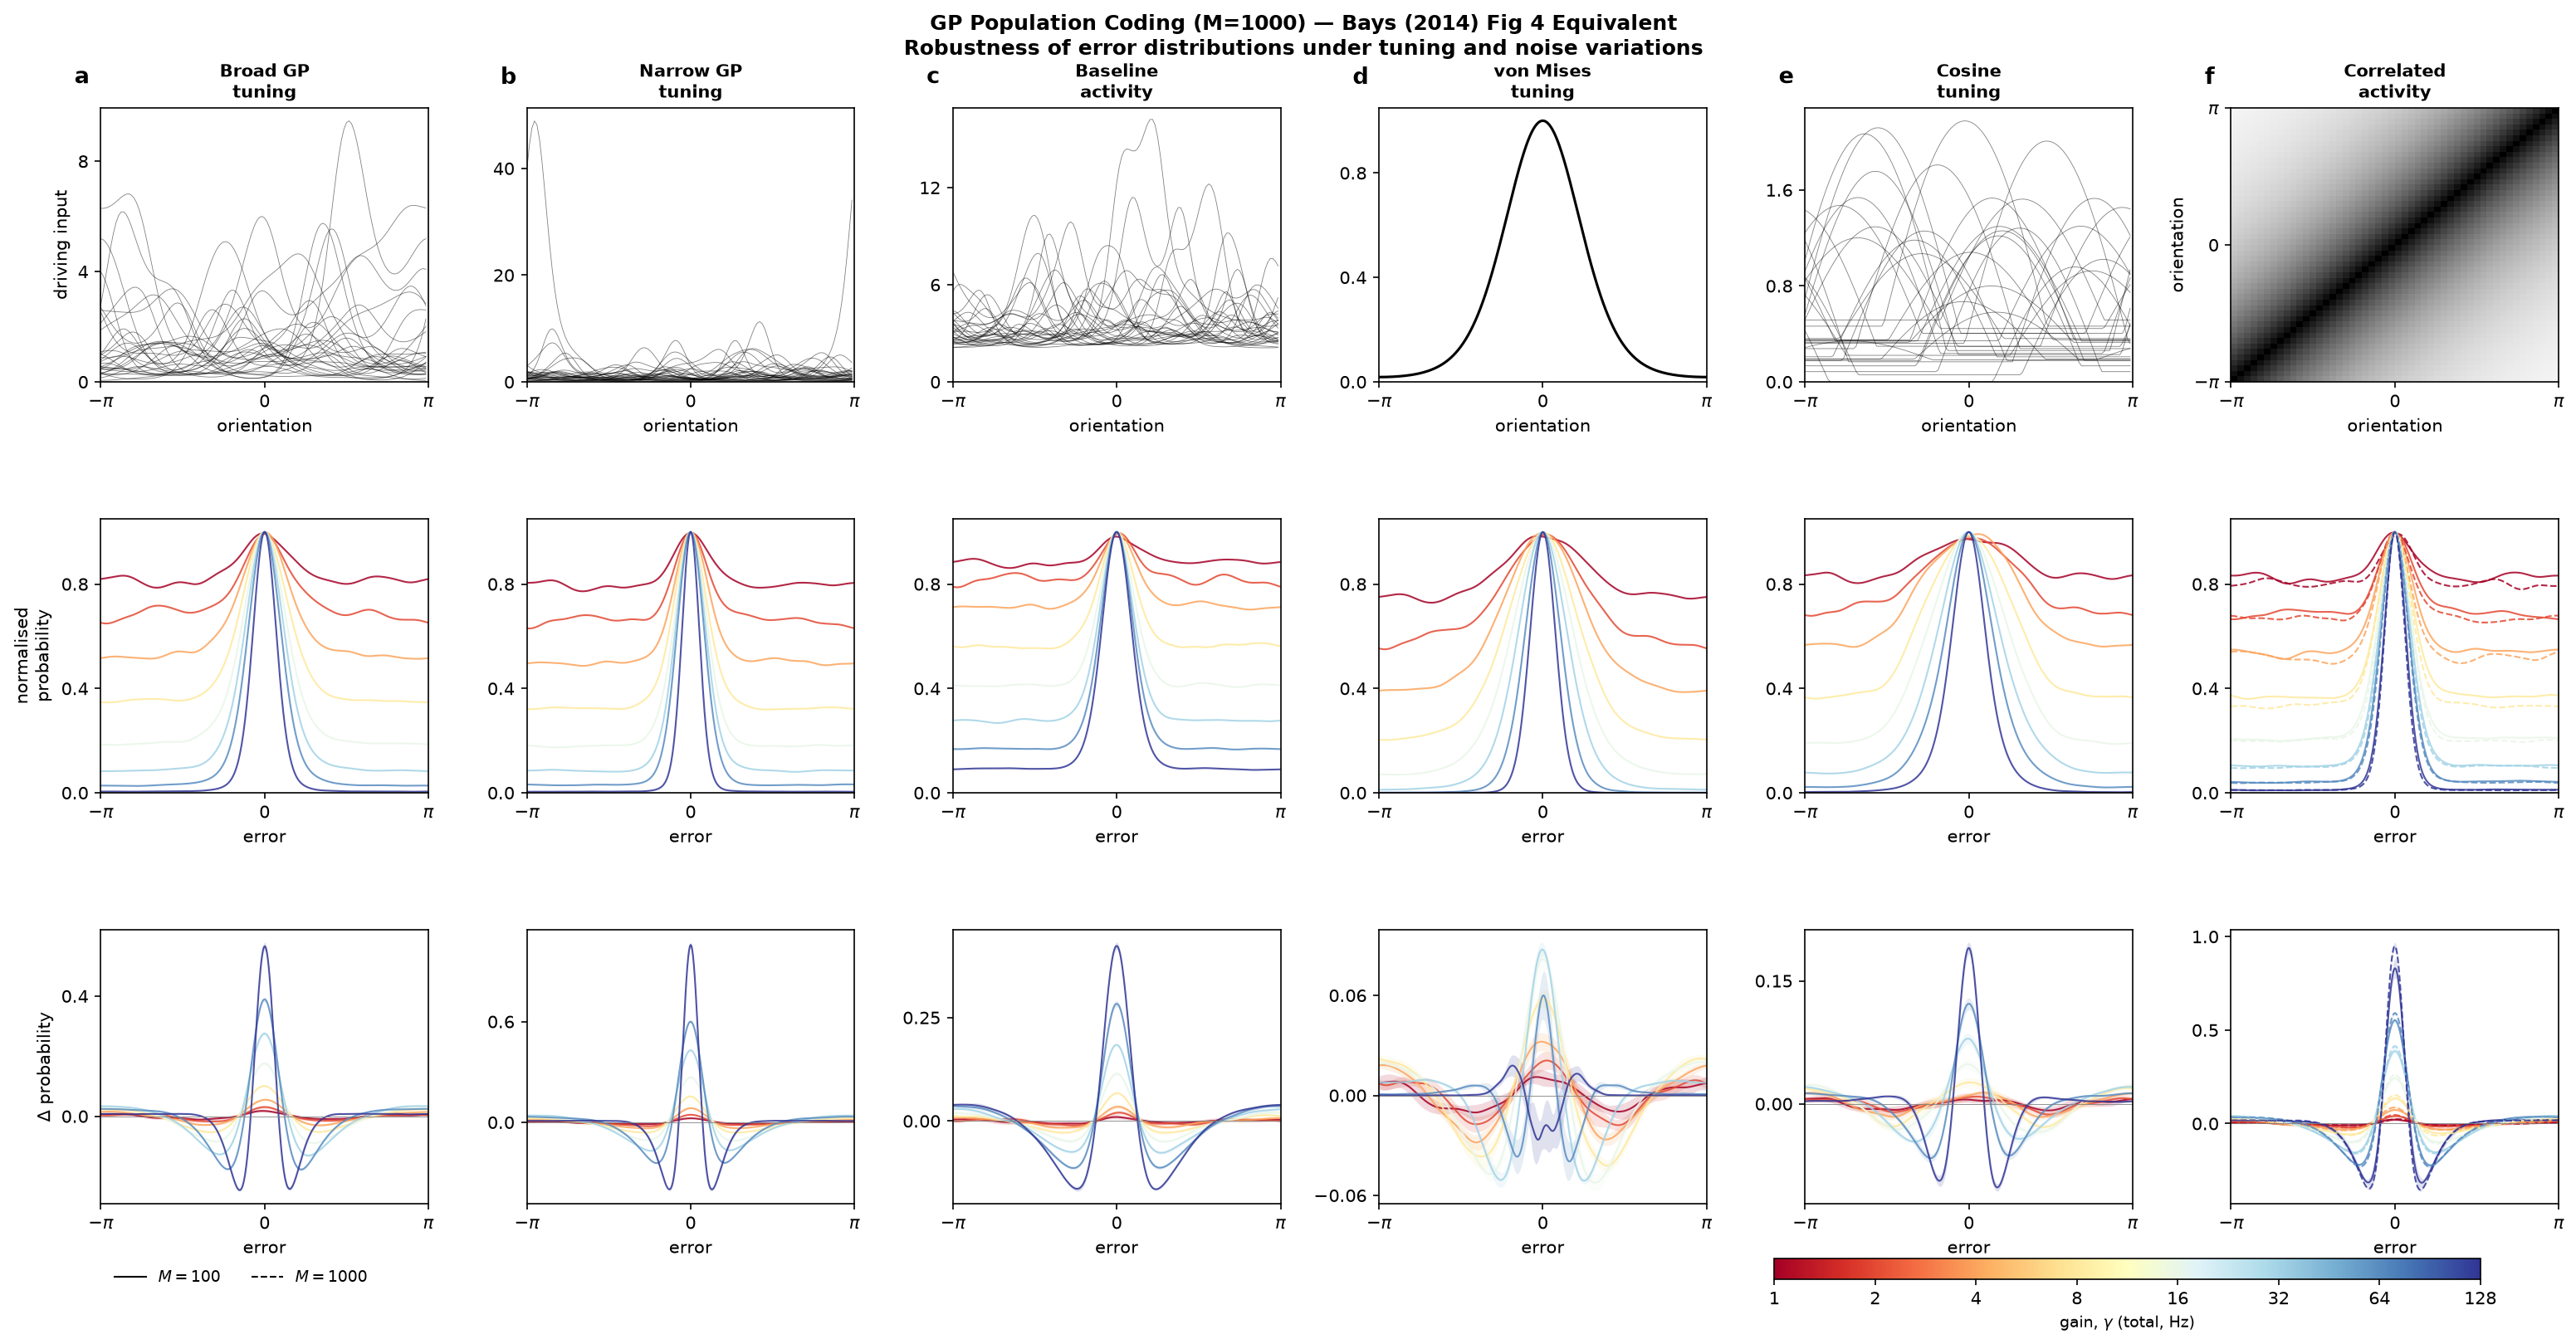

In [13]:
# === Plot: 3 rows × 6 columns — original style, now averaged over population seeds ===
# Layout, sizes, colours and labels follow the original figure. What is new:
#   * rows 2 and 3 are means over the N_SEEDS population seeds (row 1 shows seed 0);
#   * row 3 carries 95% confidence bands across seeds (SHOW_CI_BANDS);
#   * every axis keeps at least two labelled ticks (Correction 7);
#   * the panel-f loop uses its own variable, so the global M is never overwritten;
#   * a copy is saved for the thesis as thesis_figures/experiment_4/fig_4.
from matplotlib.lines import Line2D

SHOW_CI_BANDS = True
THESIS_FIG_DIR = PROJECT_ROOT / 'simulated_experiments' / 'thesis_figures' / 'experiment_4'

fig = plt.figure(figsize=(21, 11))
gs  = gridspec.GridSpec(3, 6, hspace=0.50, wspace=0.30,
                        left=0.04, right=0.98, bottom=0.08, top=0.88)

# Bays-style colormap: low gain = red, high gain = blue (logarithmic colour scale)
gain_cmap = plt.cm.RdYlBu
gain_norm = mcolors.LogNorm(vmin=min(GAMMAS_TOTAL), vmax=max(GAMMAS_TOTAL))

panel_ids = ['a', 'b', 'c', 'd', 'e', 'f']
titles    = ['Broad GP\ntuning', 'Narrow GP\ntuning', 'Baseline\nactivity',
             'von Mises\ntuning', 'Cosine\ntuning', 'Correlated\nactivity']
PI_TICKS, PI_LABELS = [-np.pi, 0, np.pi], [r'$-\pi$', '0', r'$\pi$']


def _two_tick_locator():
    return plt.MaxNLocator(nbins=3, min_n_ticks=2)


for col, pid in enumerate(panel_ids):
    runs = panels_by_seed[pid]          # one entry per population seed
    p = runs[0]                         # seed 0: the original population, for row 1
    thetas = p['thetas']
    pop_sizes = p['pop_sizes']
    M_ref = pop_sizes[0]

    # ---------- Row 1: tuning curves OR correlation matrix (seed 0) ----------
    ax_top = fig.add_subplot(gs[0, col])
    if pid == 'f':
        # Sort neurons by their mode so the tuning-similarity band is
        # visible. vmax=c0 (not 1.0) prevents the unit diagonal from
        # swamping the colour scale.
        C = p[f'corr_matrix_{M_ref}']
        sort_idx = p[f'sort_idx_{M_ref}']
        C_sorted = C[np.ix_(sort_idx, sort_idx)]
        n_show = min(50, C.shape[0])
        ax_top.imshow(C_sorted[:n_show, :n_show], cmap='gray_r',
                      origin='lower', aspect='auto',
                      vmin=0.0, vmax=C0,
                      extent=[-np.pi, np.pi, -np.pi, np.pi])
        ax_top.set_xticks(PI_TICKS); ax_top.set_xticklabels(PI_LABELS)
        ax_top.set_yticks(PI_TICKS); ax_top.set_yticklabels(PI_LABELS)
        ax_top.set_xlabel('orientation')
        ax_top.set_ylabel('orientation')
    elif pid == 'd':
        # von Mises column: homogeneous population; show a single
        # representative bump centred at θ = 0 (as in Bays Fig 4).
        omega_d = LAMBDA_BROAD ** 2
        kappa_d = 1.0 / omega_d
        theta_fine = np.linspace(-np.pi, np.pi, 400, endpoint=False)
        f_d = np.exp(kappa_d * (np.cos(theta_fine) - 1.0))
        ax_top.plot(theta_fine, f_d, 'k-', lw=1.5)
        ax_top.set_xlabel('orientation')
        if col == 0:
            ax_top.set_ylabel('driving input')
        ax_top.set_xlim(-np.pi, np.pi)
        ax_top.set_xticks(PI_TICKS); ax_top.set_xticklabels(PI_LABELS)
        ax_top.set_ylim(bottom=0)
        ax_top.yaxis.set_major_locator(_two_tick_locator())
        ax_top.axhline(0, color='k', lw=0.5, alpha=0.6)
    else:
        # GP and cosine columns: 30 evenly-indexed neurons from seed 0.
        g_full = p['g']
        if g_full.shape[0] > 30:
            idx_show = np.linspace(0, g_full.shape[0] - 1, 30).astype(int)
            g_ex = g_full[idx_show]
        else:
            g_ex = g_full
        for i in range(g_ex.shape[0]):
            ax_top.plot(thetas, g_ex[i], 'k-', lw=0.4, alpha=0.5)
        ax_top.set_xlabel('orientation')
        if col == 0:
            ax_top.set_ylabel('driving input')
        ax_top.set_xlim(-np.pi, np.pi)
        ax_top.set_xticks(PI_TICKS); ax_top.set_xticklabels(PI_LABELS)
        ax_top.set_ylim(bottom=0)
        ax_top.yaxis.set_major_locator(_two_tick_locator())
        ax_top.axhline(0, color='k', lw=0.5, alpha=0.6)

    ax_top.set_title(titles[col], fontsize=10, fontweight='bold')
    ax_top.text(-0.08, 1.15, f'$\\mathbf{{{pid}}}$',
                transform=ax_top.transAxes, fontsize=13,
                fontweight='bold', va='top')

    # ---------- Row 2: normalised error distributions (mean over seeds) ----------
    ax_mid = fig.add_subplot(gs[1, col])
    for M_p in pop_sizes:
        ls = '-' if M_p == pop_sizes[0] else '--'
        for gt in GAMMAS_TOTAL:
            key = (gt, M_p)
            curves = []
            for r in runs:
                emp = r['results'][key]['empirical']
                if emp.max() > 0:
                    curves.append(emp / emp.max())
            if curves:
                ax_mid.plot(p['results'][key]['centers'], np.mean(curves, axis=0),
                            color=gain_cmap(gain_norm(gt)),
                            lw=1.0, ls=ls, alpha=0.85)
    ax_mid.set_xlim(-np.pi, np.pi)
    ax_mid.set_ylim(0, 1.05)
    ax_mid.yaxis.set_major_locator(_two_tick_locator())
    ax_mid.set_xticks(PI_TICKS); ax_mid.set_xticklabels(PI_LABELS)
    ax_mid.set_xlabel('error')
    if col == 0:
        ax_mid.set_ylabel('normalised\nprobability')

    # ---------- Row 3: deviation from circular normal (mean, 95% band) ----------
    ax_bot = fig.add_subplot(gs[2, col])
    for M_p in pop_sizes:
        ls = '-' if M_p == pop_sizes[0] else '--'
        for gt in GAMMAS_TOTAL:
            key = (gt, M_p)
            devs = np.array([r['results'][key]['deviation'] for r in runs])
            m, lo, hi = mean_ci(devs)
            x = p['results'][key]['centers']
            color = gain_cmap(gain_norm(gt))
            if SHOW_CI_BANDS:
                ax_bot.fill_between(x, lo, hi, color=color, alpha=0.15, lw=0)
            ax_bot.plot(x, m, color=color, lw=1.0, ls=ls, alpha=0.85)
    ax_bot.axhline(0, color='gray', lw=0.4)
    ax_bot.set_xlim(-np.pi, np.pi)
    ax_bot.yaxis.set_major_locator(_two_tick_locator())
    ax_bot.set_xticks(PI_TICKS); ax_bot.set_xticklabels(PI_LABELS)
    ax_bot.set_xlabel('error')
    if col == 0:
        ax_bot.set_ylabel(r'$\Delta$ probability')

# ---------- Legend & colorbar ----------
handles = [Line2D([0], [0], color='k', lw=1, ls='-',  label=r'$M=100$'),
           Line2D([0], [0], color='k', lw=1, ls='--', label=r'$M=1000$')]
fig.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.04, 0.01),
           fontsize=9, frameon=False, ncol=2)

sm = plt.cm.ScalarMappable(cmap=gain_cmap, norm=gain_norm)
sm.set_array([])
cbar_ax = fig.add_axes([0.68, 0.025, 0.27, 0.015])
cb = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cb.set_label(r'gain, $\gamma$ (total, Hz)', fontsize=9)
cb.set_ticks(GAMMAS_TOTAL)
cb.set_ticklabels([str(g) for g in GAMMAS_TOTAL])
cb.ax.xaxis.set_minor_locator(plt.NullLocator())

fig.suptitle(
    f'GP Population Coding (M={M_DEFAULT}) — Bays (2014) Fig 4 Equivalent\n'
    'Robustness of error distributions under tuning and noise variations',
    fontsize=12, fontweight='bold', y=0.95,
)

# Save: run folder (as before) plus the thesis copy (images/results/fig_4.png).
saved = []
for folder, name in ((OUTPUT_DIR, f'bays_fig4_M{M_DEFAULT}_{N_SEEDS}seeds'),
                     (THESIS_FIG_DIR, 'fig_4')):
    folder.mkdir(parents=True, exist_ok=True)
    for ext in ('png', 'pdf'):
        path = (folder / f'{name}.{ext}').resolve()
        fig.savefig(path, dpi=300, bbox_inches='tight')
        saved.append(path)
missing = [str(path) for path in saved if not path.exists()]
if missing:
    raise IOError(f'Figure not written: {missing}')
print('Saved:\n  ' + '\n  '.join(str(path) for path in saved))
print(f'  For the caption: all axes linear; the gain colour scale is logarithmic '
      f'(1-128 Hz). Rows 2 and 3 are means over {N_SEEDS} population seeds'
      + (', with 95% confidence bands on row 3' if SHOW_CI_BANDS else '')
      + '; row 1 shows the seed-0 population.')
plt.show()

In [14]:
# === Save results: seed-averaged summary table and raw per-seed results ===
import csv

summary_path = OUTPUT_DIR / 'exp4_summary_by_panel_gain.csv'
with open(summary_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['panel', 'M', 'gamma_total_hz', 'n_seeds',
                'variance_geomean', 'variance_ci_lo', 'variance_ci_hi',
                'kurtosis_mean', 'kurtosis_ci_lo', 'kurtosis_ci_hi',
                'deviation_at_zero_mean', 'deviation_at_zero_ci_lo', 'deviation_at_zero_ci_hi',
                'deviation_size_mean', 'deviation_size_ci_lo', 'deviation_size_ci_hi'])
    for row in summary_rows:
        w.writerow([row['panel'], row['M'], row['gamma_total'], row['n_seeds'],
                    *row['variance'], *row['kurtosis'],
                    *row['deviation_at_zero'], *row['deviation_size']])

raw_path = OUTPUT_DIR / 'exp4_seed_results.pkl'
with open(raw_path, 'wb') as f:
    pickle.dump({'config': _run_config, 'N_SEEDS': N_SEEDS,
                 'panels_by_seed': panels_by_seed}, f)

print('Saved:')
for p in (summary_path, raw_path):
    print(f'  {p}')

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_4/20261020/shared_kernel_1000_gp_10seeds/150741/exp4_summary_by_panel_gain.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_4/20261020/shared_kernel_1000_gp_10seeds/150741/exp4_seed_results.pkl
